# Skin to CAD: segment, fit, hand off as STEP

A triangle skin -- an STL from a scan or a 3-D-printing download -- is thousands of
flat facets a CAD tool cannot dimension or edit. meshio++ does the mesh-side half of
reverse engineering it with no CAD kernel in the loop, and the CAD half through an
optional OpenCASCADE backend:

- **`segment`** groups the facets into smooth patches bounded by the feature edges,
  with a curvature test that separates a fillet from the faces it is tangent to;
- **`fit_primitives`** fits a plane, sphere, cylinder, cone or torus to each patch and
  reports the residual -- a recovered radius or axis is a measurement;
- the **`step`** writer hands the closed skin to CAD as a faceted solid;
- **`fit_cad`** (a core built with `-DMESHIOPLUSPLUS_WITH_OCCT=ON`) turns the fitted
  patches into analytic CAD faces, sewn into a checked solid and written as STEP.

The part here is a noisy, tessellated turned part with every primitive type in it.
See [skin to CAD](../../doc/cad_fit.md).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')
TYPES = ['none', 'plane', 'sphere', 'cylinder', 'cone', 'torus']
TYPE_COLORS = ['#888888', '#4c78a8', '#f58518', '#54a24b', '#e45756', '#b279a2']


def to_grid(mesh):
    '''A PyVista grid of a meshio++ mesh, through a temporary .vtu.'''
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='tab10', clim=None, annotations=None, save=None):
    '''Render with PyVista, or the points with matplotlib when GL is unavailable.'''
    fig, ax = plt.subplots(figsize=(9, 6))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(1000, 720))
        kwargs = {'show_edges': True, 'edge_color': '#333333', 'line_width': 0.2}
        if scalars is not None:
            bar = {'title': scalars, 'vertical': True, 'position_x': 0.86,
                   'position_y': 0.15, 'height': 0.7, 'width': 0.06}
            if annotations:
                bar['n_labels'] = 0
            kwargs.update(scalars=scalars, cmap=cmap, clim=clim, categories=True,
                          annotations=annotations, scalar_bar_args=bar)
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector((1.0, -1.6, 0.9), viewup=(0, 0, 1))
        pl.reset_camera()
        pl.camera.zoom(1.15)
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
        if save:
            try:
                os.makedirs(DOC_IMAGES, exist_ok=True)
                plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
            except Exception as exc:  # pragma: no cover - read-only checkout
                print('doc image not written:', exc)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 2], s=1)
    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## A noisy turned part

A surface of revolution closed by two triangle fans: a flat **base**, a **cylinder**
wall, a toroidal **fillet** tangent to the wall and to a flat **shoulder**, a
**cone**, and a shallow spherical **dome**. The base, shoulder, cone and dome meet
their neighbours at creases; the fillet meets the wall and the shoulder tangentially,
so only its curvature tells it apart. Every point is moved by up to `1e-3`, a scan's
noise.

points: 2178  cells: 2240
{'boundary_edges': 0, 'non_manifold_edges': 0, 'inconsistent_pairs': 0, 'degenerate_triangles': 0, 'watertight': True}


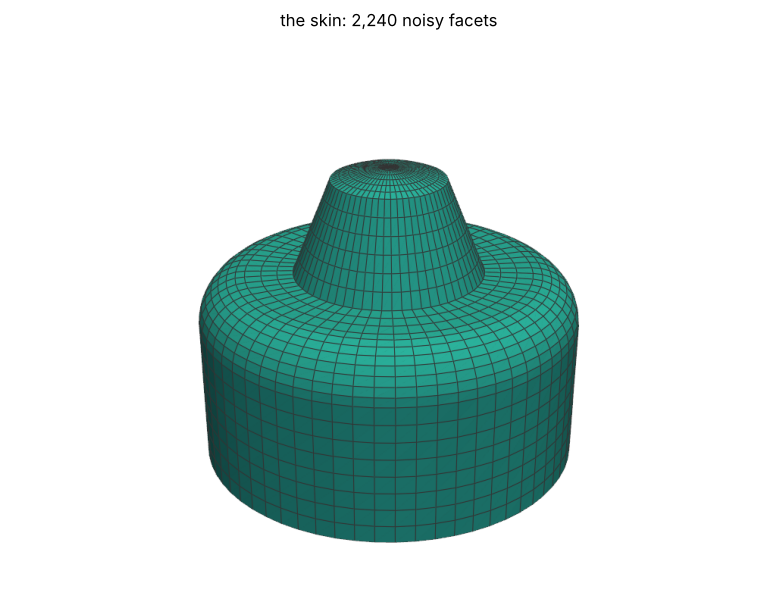

In [2]:
def turned_part(n=64, noise=0.0, seed=7):
    prof = [(2.0 * i / 4, 0.0) for i in range(1, 5)]                       # base
    prof += [(2.0, 1.5 * i / 8) for i in range(1, 9)]                       # wall
    prof += [(1.5 + 0.5 * np.cos(a), 1.5 + 0.5 * np.sin(a))                 # fillet
             for a in np.linspace(0.0, np.pi / 2, 9)[1:]]
    prof += [(1.5 - 0.5 * i / 3, 2.0) for i in range(1, 4)]                 # shoulder
    prof += [(1.0 - 0.4 * i / 6, 2.0 + 1.0 * i / 6) for i in range(1, 7)]   # cone
    zc, big_r = 1.625, 1.5                                                   # dome
    a0 = np.arcsin(0.6 / big_r)
    prof += [(big_r * np.sin(a), zc + big_r * np.cos(a)) for a in np.linspace(a0, 0.0, 7)[1:-1]]
    pts = [[0.0, 0.0, 0.0]]
    for r, z in prof:
        for k in range(n):
            t = 2.0 * np.pi * k / n
            pts.append([r * np.cos(t), r * np.sin(t), z])
    top = len(pts)
    pts.append([0.0, 0.0, zc + big_r])
    ring = lambda i, k: 1 + i * n + (k % n)  # noqa: E731
    last = len(prof) - 1
    tris = [[0, ring(0, k + 1), ring(0, k)] for k in range(n)]
    tris += [[top, ring(last, k), ring(last, k + 1)] for k in range(n)]
    quads = [[ring(i, k), ring(i, k + 1), ring(i + 1, k + 1), ring(i + 1, k)]
             for i in range(last) for k in range(n)]
    pts = np.array(pts)
    if noise:
        pts = pts + noise * np.random.default_rng(seed).uniform(-1.0, 1.0, pts.shape)
    return mp.Mesh(pts, [('triangle', np.array(tris)), ('quad', np.array(quads))])


part = turned_part(noise=1e-3)
print('points:', len(part.points), ' cells:', sum(len(c.data) for c in part.cells))
print(mp.surface_watertight_check(part))
render(part, 'the skin: 2,240 noisy facets')

## Segment

The feature edges alone find four patches: the fillet joins the wall and the shoulder,
because nothing creases between them. `curvature_tolerance` compares each cell's
curvature estimate (about the larger principal curvature: `1/r` on the wall, `1/0.5`
on the fillet, `0` on the planes) with the mean of the patch it would join; the noise
makes a few slivers near the poles, which `min_patch_cells` folds back in.

creases only     : 4 patches
with curvature   : {'num_patches': 6, 'num_merged': 85, 'num_feature_edges': 192, 'num_boundary_edges': 0, 'num_non_manifold_edges': 0}
patch sizes      : [256, 384, 512, 512, 192, 384]
adjacency (a, b, shared edges):
[[ 0  2 64]
 [ 1  5 64]
 [ 2  3 64]
 [ 3  4 64]
 [ 4  5 64]]


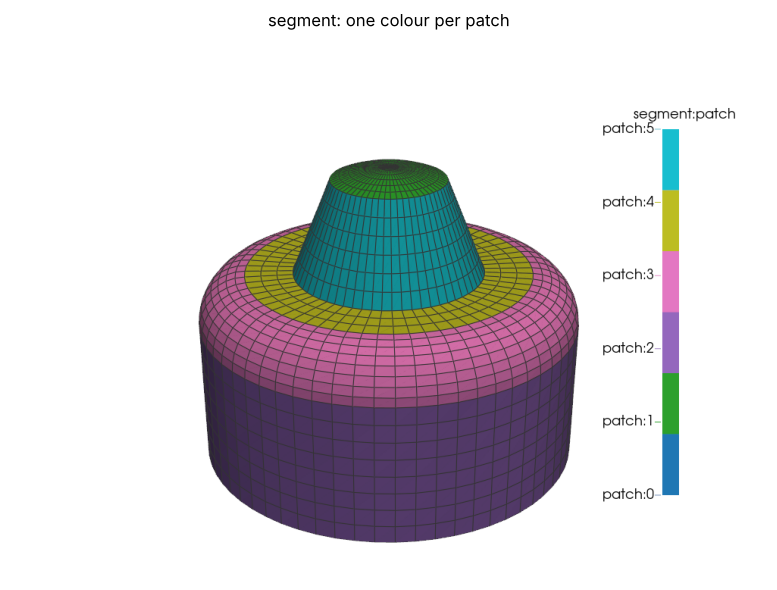

In [3]:
creases_only = mp.segment(part, return_report=True)[1]
print('creases only     :', creases_only['num_patches'], 'patches')

seg, report = mp.segment(part, curvature_tolerance=1.0, min_patch_cells=20, return_report=True)
print('with curvature   :', report)
print('patch sizes      :', np.bincount(np.concatenate(seg.cell_data['segment:patch'])).tolist())
print('adjacency (a, b, shared edges):')
print(seg.field_data['segment:adjacency'])
patches = {k: f'patch:{k}' for k in range(report['num_patches'])}
render(seg, 'segment: one colour per patch', scalars='segment:patch',
       annotations=patches, save='skin_to_cad_patches')

## Fit primitives

Each patch is fitted with every type, refined by Levenberg-Marquardt on the orthogonal
distance, and the simplest type within tolerance (here `2e-3` of the patch's diagonal)
wins. The parameters are the measurement: the wall's radius is 2, the fillet a torus of
major radius 1.5 and minor radius 0.5, the cone's half-angle 21.8 degrees, the dome a
sphere of radius 1.5 -- recovered through the noise, with the residual to prove it.

In [4]:
fit, fit_report = mp.fit_primitives(seg, tolerance=2e-3, return_report=True)
print(fit_report)
fd = fit.field_data
print(f"{'patch':>5} {'type':>9} {'rms':>9}  parameters")
for pid, t, p, rms in zip(fd['fit:patch_id'], fd['fit:patch_type'],
                          fd['fit:patch_params'], fd['fit:patch_rms']):
    name = TYPES[t]
    if name == 'plane':
        what = f'normal {np.round(p[3:6], 3)}'
    elif name == 'sphere':
        what = f'centre {np.round(p[:3], 3)}, radius {p[6]:.4f}'
    elif name == 'cylinder':
        what = f'axis {np.round(p[3:6], 3)}, radius {p[6]:.4f}'
    elif name == 'cone':
        what = f'apex {np.round(p[:3], 3)}, half-angle {p[8]:.2f} deg'
    else:
        what = f'major {p[6]:.4f}, minor {p[7]:.4f}'
    print(f'{pid:>5} {name:>9} {rms:9.2e}  {what}')

{'num_patches': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_unfitted': 0}
patch      type       rms  parameters
    0     plane  5.81e-04  normal [-0.  0. -1.]
    1    sphere  5.52e-04  centre [-0.    -0.     1.624], radius 1.5006
    2  cylinder  5.78e-04  axis [-0. -0.  1.], radius 2.0000
    3     torus  5.70e-04  major 1.5001, minor 0.4998
    4     plane  5.30e-04  normal [-0.  0.  1.]
    5      cone  5.77e-04  apex [0.  0.  4.5], half-angle 21.80 deg


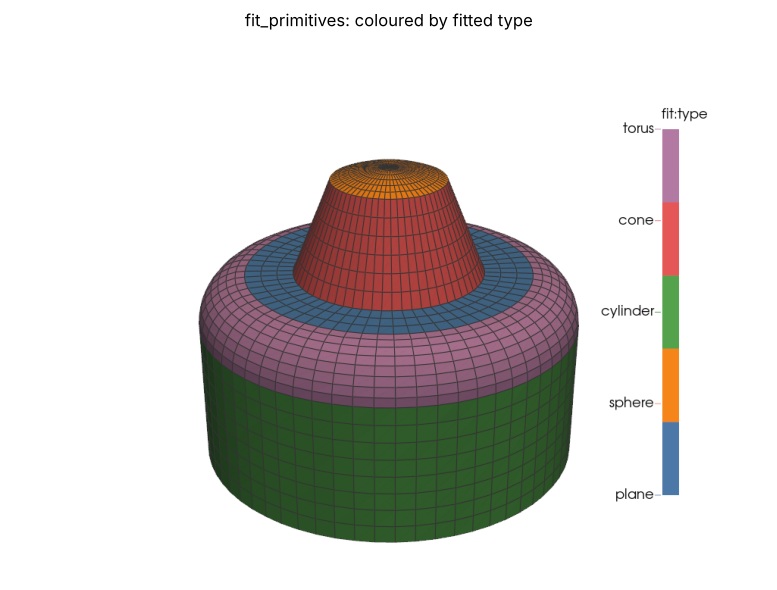

In [5]:
annotations = {i: TYPES[i] for i in range(1, 6)}
render(fit, 'fit_primitives: coloured by fitted type', scalars='fit:type',
       cmap=TYPE_COLORS[1:], clim=[1, 5], annotations=annotations, save='skin_to_cad_fits')

## A fit that does not hold is reported, not rounded

With the tolerance tighter than the noise, nothing is accepted: every patch comes back
as `none` with its best residual, so a downstream tool never mistakes noise for a
primitive.

In [6]:
tight = mp.fit_primitives(seg, tolerance=1e-5, return_report=True)[1]
print(tight)

{'num_patches': 6, 'num_plane': 0, 'num_sphere': 0, 'num_cylinder': 0, 'num_cone': 0, 'num_torus': 0, 'num_unfitted': 6}


## Hand off as STEP

The closed skin goes to CAD as a faceted solid: one planar `ADVANCED_FACE` per facet
(non-planar noisy quads are fanned into triangles), shared edges, one
`MANIFOLD_SOLID_BREP`. A CAD tool opens it as a solid it can measure and section; the
fitted parameters above say which faces belong to which cylinder or cone.

In [7]:
step_path = os.path.join(TMP, 'turned_part.step')
mp.write(step_path, part)
text = open(step_path).read()
print('\n'.join(text.splitlines()[:9]))
for entity in ('ADVANCED_FACE', 'EDGE_CURVE', 'VERTEX_POINT', 'MANIFOLD_SOLID_BREP'):
    print(f'{entity:>20}: {text.count("=" + entity + "(")}')

ISO-10303-21;
/*
Written by meshio++ v16.40.0
*/
HEADER;
FILE_DESCRIPTION(('meshio++ faceted B-rep'),'2;1');
FILE_NAME('turned_part.step','1970-01-01T00:00:00',(''),(''),'meshio++','meshio++','');
FILE_SCHEMA(('AUTOMOTIVE_DESIGN { 1 0 10303 214 1 1 1 1 }'));
ENDSEC;
       ADVANCED_FACE: 4352
          EDGE_CURVE: 6528
        VERTEX_POINT: 2178
 MANIFOLD_SOLID_BREP: 1


## Analytic CAD faces with `fit_cad`

The faceted solid is a hand-off; the fitted surfaces are what a CAD tool wants. With the
optional OpenCASCADE backend, `fit_cad` makes each accepted patch one face on its fitted
surface, trimmed by the patch boundary: exact circles where a plane meets the cylinder,
the cone or the dome, B-splines where the fillet meets the wall and the shoulder
tangentially. OpenCASCADE sews and checks the solid, and any face it rejects, or that
strays further than the tolerance from the skin, would come back faceted and be counted
in `num_demoted`. The report compares the solid with the skin: its volume ratio and the
Hausdorff deviation of its re-meshed surface. See [fit CAD](../../doc/fit_cad.md).

{'valid': True, 'num_faces': 6, 'num_plane': 2, 'num_sphere': 1, 'num_cylinder': 1, 'num_cone': 1, 'num_torus': 1, 'num_faceted_faces': 0, 'num_demoted': 0, 'num_exact_edges': 5, 'num_approx_edges': 5}
volume ratio 1.00218, max deviation 8.91e-03 (tolerance 3.51e-02)
               PLANE: 2
 CYLINDRICAL_SURFACE: 1
     CONICAL_SURFACE: 1
   SPHERICAL_SURFACE: 1
    TOROIDAL_SURFACE: 1
       ADVANCED_FACE: 6


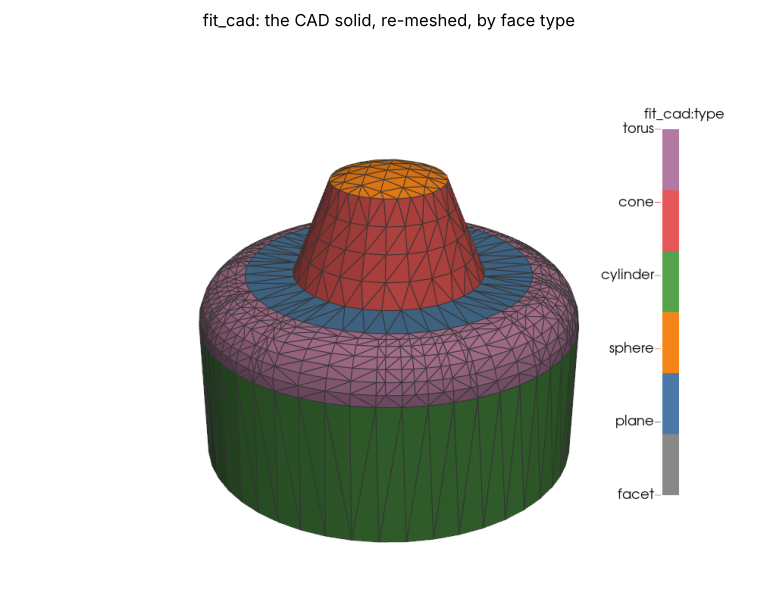

In [8]:
from meshioplusplus._fit_cad import has_occt

if has_occt():
    cad_path = os.path.join(TMP, 'turned_part_cad.step')
    solid, cad = mp.fit_cad(fit, cad_path, return_report=True)
    print({k: cad[k] for k in ('valid', 'num_faces', 'num_plane', 'num_sphere', 'num_cylinder',
                                'num_cone', 'num_torus', 'num_faceted_faces', 'num_demoted',
                                'num_exact_edges', 'num_approx_edges')})
    print(f"volume ratio {cad['volume_ratio']:.5f}, max deviation {cad['max_deviation']:.2e}"
          f" (tolerance {cad['tolerance']:.2e})")
    text = open(cad_path).read()
    for entity in ('PLANE', 'CYLINDRICAL_SURFACE', 'CONICAL_SURFACE', 'SPHERICAL_SURFACE',
                   'TOROIDAL_SURFACE', 'ADVANCED_FACE'):
        print(f'{entity:>20}: {text.count("= " + entity + "(")}')
    render(solid, 'fit_cad: the CAD solid, re-meshed, by face type', scalars='fit_cad:type',
           cmap=TYPE_COLORS, clim=[0, 5], annotations={0: 'facet', **{i: TYPES[i] for i in range(1, 6)}},
           save='fit_cad_solid')
else:
    print('This core has no OpenCASCADE backend: rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON '
          'to build the analytic solid (see doc/fit_cad.md).')